# UTS Pembelajaran Mesin C

## Implementasi Algoritma KNN

## Import Library

In [1]:
import pandas as pd # 202431163_maftuh faisal jauhari
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

### Load Dataset & Preprocessing
Mengambil data Teh, membersihkan missing value, memfilter 0 struktural, dan capping outlier.

In [2]:
# 202431163_maftuh faisal jauhari
df_raw = pd.read_csv("31_Luas_lahan_perkebunan_komoditas_strategis.csv", skiprows=10, header=None)

data = df_raw[[1, 46, 47]].copy()
data.columns = ['Provinsi', 'Teh_2020', 'Teh_2021']

data = data.dropna(subset=['Provinsi'])
data = data[data['Provinsi'] != 'Indonesia']

data = data.replace("-", np.nan)
data['Teh_2020'] = pd.to_numeric(data['Teh_2020'], errors='coerce')
data['Teh_2021'] = pd.to_numeric(data['Teh_2021'], errors='coerce')
data = data.dropna()

data = data[data['Teh_2020'] > 0]

data.loc[data['Teh_2020'] > 13775.13, 'Teh_2020'] = 13775.13

data

,Provinsi,Teh_2020,Teh_2021
1,Sumatera Utara,6058.750,4222.020
2,Sumatera Barat,3714.160,2876.130
4,Jambi,1797.610,1951.000
5,Sumatera Selatan,1522.690,1522.690
6,Bengkulu,914.500,914.230
11,Jawa Barat,13775.130,79376.440
12,Jawa Tengah,9050.518,8895.328
13,DI Yogyakarta,136.500,136.000
14,Jawa Timur,2187.000,2083.910
15,Banten,94.500,100.000


### Memisahkan Fitur (X) dan Target (Y)

In [3]:
x = data[['Teh_2020']] # 202431163_maftuh faisal jauhari
y = data['Teh_2021']

display(x)
display(y)

,Teh_2020
1,6058.750
2,3714.160
4,1797.610
5,1522.690
6,914.500
11,13775.130
12,9050.518
13,136.500
14,2187.000
15,94.500


1      4222.020
2      2876.130
4      1951.000
5      1522.690
6       914.230
11    79376.440
12     8895.328
13      136.000
14     2083.910
15      100.000
Name: Teh_2021, dtype: float64

### Split Data (Train & Test)

In [4]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42) # 202431163_maftuh faisal jauhari

### Modeling KNN Regression (Fitting)
Kita menggunakan K=3 sesuai dengan perhitungan manual.

In [5]:
# 202431163_maftuh faisal jauhari
knn = KNeighborsRegressor(n_neighbors=3)
knn.fit(x_train, y_train)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",3
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Uniform weights are used by default.See the following example for a demonstration of the impact ofdifferent weighting schemes on predictions::ref:`sphx_glr_auto_examples_neighbors_plot_regression.py`.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this isequivalent to using manhattan_distance (l1), and euclidean_distance(l2) for p = 2. For arbitrary p, minkowski_distance (l_p) is used.",2
,"metric metric: str, DistanceMetric object or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.If metric is a DistanceMetric object, it will be passed directly tothe underlying computation routines.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"effective_metric_ effective_metric_: str or callableThe distance metric to use. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'
"effective_metric_params_ effective_metric_params_: dictAdditional keyword arguments for the metric function. For most metricswill be same with `metric_params` parameter, but may also contain the`p` parameter value if the `effective_metric_` attribute is set to'minkowski'.",dict,{}


### Prediksi Data Uji

In [6]:
y_pred = knn.predict(x_test) # 202431163_maftuh faisal jauhari
print(y_pred)

[1462.64       2565.23666667]


### Evaluasi Model
Karena ini regresi, kita pakai MAE, RMSE, dan R2 (bukan accuracy_score).

In [7]:
mae = mean_absolute_error(y_test, y_pred) # 202431163_maftuh faisal jauhari

rmse = np.sqrt(mean_squared_error(y_test, y_pred)) 
r2 = r2_score(y_test, y_pred)

print("MAE :", mae)
print("RMSE:", rmse)
print("R2  :", r2)

MAE : 466.08166666666637
RMSE: 491.238779826629
R2  : -0.5379905778538319


### Plot Pemilihan Nilai K (Elbow Method)
Mencari nilai K terbaik dengan melihat tingkat error terendah.

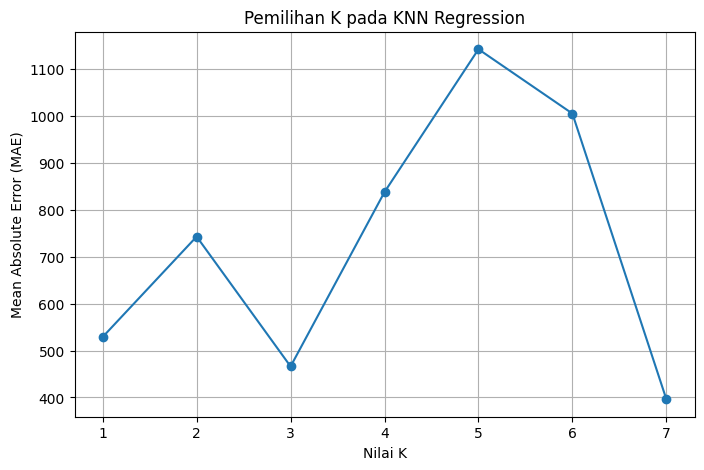

In [8]:
k_values = range(1, 8) # 202431163_maftuh faisal jauhari
maes = []

for k in k_values:
    model = KNeighborsRegressor(n_neighbors=k)
    model.fit(x_train, y_train)
    pred = model.predict(x_test)
    error = mean_absolute_error(y_test, pred)
    maes.append(error)

plt.figure(figsize=(8, 5))
plt.plot(k_values, maes, marker='o')
plt.xlabel("Nilai K")
plt.ylabel("Mean Absolute Error (MAE)")
plt.title("Pemilihan K pada KNN Regression")
plt.grid(True)
plt.show()

### Visualisasi Hasil Prediksi

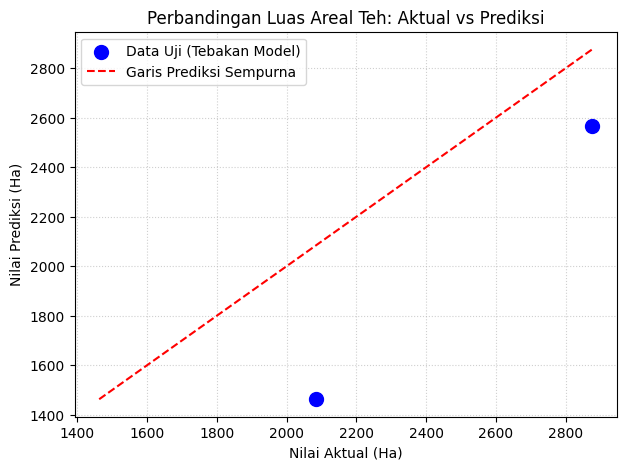

In [9]:
plt.figure(figsize=(7, 5))

plt.scatter(y_test, y_pred, color='blue', label='Data Uji (Tebakan Model)', s=100)

# 202431163_maftuh faisal jauhari
min_val = min(y_test.min(), y_pred.min())
max_val = max(y_test.max(), y_pred.max())
plt.plot([min_val, max_val], [min_val, max_val], color='red', linestyle='--', label='Garis Prediksi Sempurna')

plt.title('Perbandingan Luas Areal Teh: Aktual vs Prediksi')
plt.xlabel('Nilai Aktual (Ha)')
plt.ylabel('Nilai Prediksi (Ha)')
plt.legend()
plt.grid(True, linestyle=':', alpha=0.6)
plt.show()